# Proyecto 8: clasificación de hojas de caña de azúcar

En este proyecto trabajamos con un conjunto de imágenes de hojas de caña de azúcar que presentan diferentes enfermedades, además de hojas que no muestran síntomas visibles.

Nuestro propósito es analizar si, a partir de las características de color y textura de las fotografías, podemos diferenciar las cinco categorías presentes en el dataset.

Para esto utilizamos herramientas de procesamiento de imágenes y dos modelos de aprendizaje supervisado: Naive Bayes y SVM. A partir de los resultados obtenidos, comparamos su desempeño y analizamos qué tan bien logran clasificar las imágenes.

También evaluamos si elementos como el fondo, la iluminación y las características de las fotografías pueden influir en los resultados del modelo.

## Pregunta

¿Qué tan bien permiten las características de color y textura clasificar las fotografías de hojas de caña de azúcar en las cinco categorías del dataset y qué tanto influye el contexto de las imágenes en esta clasificación?

## Objetivo general

Comparar el desempeño de los modelos Naive Bayes y SVM para clasificar imágenes de hojas de caña de azúcar mediante características de color y textura, evaluando también la influencia del contexto de las fotografías.

## Alcance del proyecto

Este trabajo se enfoca en la clasificación de imágenes a partir de las categorías proporcionadas por el dataset. Los resultados permiten analizar el comportamiento de los modelos, pero no representan un diagnóstico definitivo de las enfermedades ni han sido validados directamente en cultivos colombianos.

## 1. Bibliotecas y carpetas

Para comenzar, importamos las bibliotecas que necesitamos para desarrollar el proyecto.

Utilizamos NumPy y pandas para organizar y trabajar con los datos, Pillow para leer y procesar las imágenes, y SciPy para realizar algunas operaciones relacionadas con su análisis.

También usamos matplotlib para visualizar los resultados y scikit-learn para entrenar y evaluar los modelos de clasificación.

Estas herramientas nos permiten trabajar con las fotografías, extraer sus características y posteriormente comparar los resultados de los modelos.

En esta parte también definimos las carpetas donde se almacenarán los archivos y los resultados generados durante el análisis.

In [ ]:
from pathlib import Path
import os, json, hashlib, urllib.request, zipfile, platform, importlib.metadata
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy.fft import dctn
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
BASE = Path.cwd()
SALIDA = BASE / 'resultados'
SALIDA.mkdir(exist_ok=True)
VERSIONES = {n: importlib.metadata.version(n) for n in
             ['numpy','pandas','pillow','scipy','matplotlib','scikit-learn']}
print('Python:', platform.python_version())
print(VERSIONES)


Python: 3.13.18
{'numpy': '2.1.3', 'pandas': '2.2.3', 'pillow': '11.3.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'scikit-learn': '1.6.1'}


## 2. Descarga y revisión del dataset

Para desarrollar el proyecto utilizamos el conjunto de datos *Sugarcane Leaf Disease Classification Dataset*, disponible públicamente en Kaggle.

**Fuente:** https://www.kaggle.com/datasets/anant1302/sugarcane-leaf-disease-classification-dataset

Trabajamos con la versión 1 del dataset, que contiene 2.521 fotografías en formato JPEG, organizadas en cinco categorías:

- **Asymptomatic:** hojas sin síntomas visibles.
- **Colletotrichosis:** hojas clasificadas con colletotricosis.
- **Puccinia:** hojas clasificadas con roya.
- **SCMV:** hojas clasificadas con el virus del mosaico.
- **SCYLV:** hojas clasificadas con el virus de la hoja amarilla.

En esta parte descargamos los archivos y comprobamos que las imágenes estuvieran disponibles para continuar con el análisis.

Es importante aclarar que utilizamos las categorías originales del dataset. Por lo tanto, estas etiquetas no corresponden a diagnósticos realizados directamente por nuestro equipo.

In [ ]:
ZIP_LOCAL = ''  # Ejemplo alternativo en Colab: '/content/archive.zip'
DATASET = BASE / 'datos_cana'
URL = 'https://www.kaggle.com/api/v1/datasets/download/anant1302/sugarcane-leaf-disease-classification-dataset?datasetVersionNumber=1'
if not DATASET.exists() or not any(DATASET.rglob('*.jpg')):
    archivo_zip = Path(ZIP_LOCAL) if ZIP_LOCAL else BASE / 'sugarcane_v1.zip'
    if not archivo_zip.exists():
        print('Descargando el dataset (aproximadamente 167 MB)...')
        with urllib.request.urlopen(URL, timeout=90) as entrada, archivo_zip.open('wb') as destino:
            while bloque := entrada.read(1024*1024):
                destino.write(bloque)
    DATASET.mkdir(exist_ok=True)
    with zipfile.ZipFile(archivo_zip) as z:
        for n in z.namelist():
            destino = (DATASET / n).resolve()
            if not destino.is_relative_to(DATASET.resolve()):
                raise ValueError('Ruta no válida dentro del ZIP')
        z.extractall(DATASET)
CLASES = ['Asymptomatic','Colletotrichosis','Puccinia','SCMV','SCYLV']
archivos = sorted(p for p in DATASET.rglob('*')
                  if p.suffix.lower() in {'.jpg','.jpeg','.png'} and p.parent.name in CLASES)
assert archivos, 'No se encontraron imágenes: revisar la descarga y las carpetas.'
print('Imágenes encontradas:',len(archivos))
print(pd.Series(Counter(p.parent.name for p in archivos)).to_string())


Descargando el dataset (aproximadamente 167 MB)...
Imágenes encontradas: 2521
Asymptomatic        522
Colletotrichosis    518
Puccinia            514
SCMV                462
SCYLV               505


## 3. Revisión de calidad y eliminación de duplicados

Antes de comenzar con el análisis, revisamos las imágenes del dataset para comprobar que se pudieran abrir correctamente e identificar fotografías repetidas.

Para esto utilizamos dos métodos:

- **Hash SHA-256:** nos permitió identificar imágenes exactamente iguales a partir de sus píxeles, para evitar trabajar varias veces con la misma fotografía.
- **Hash perceptual (pHash):** lo utilizamos para identificar imágenes visualmente muy parecidas, incluso cuando pueden tener pequeñas diferencias. En este caso trabajamos con una distancia máxima de 4 bits.

Esta revisión es importante porque, si una misma imagen o una fotografía muy parecida aparece tanto en el entrenamiento como en la prueba, los resultados del modelo pueden parecer mejores de lo que realmente son.

Después de realizar la revisión, identificamos 210 imágenes duplicadas exactas, que fueron eliminadas. De esta manera, pasamos de 2.521 fotografías originales a 2.311 imágenes para continuar con el análisis.

También debemos tener en cuenta que el pHash es una aproximación y no garantiza que las fotografías correspondan a plantas diferentes, ya que el dataset no incluye información que permita identificar cada planta o lote.

In [ ]:
def leer_rgb(ruta):
    with Image.open(ruta) as im:
        return ImageOps.exif_transpose(im).convert('RGB')

def phash(im):
    gris = np.asarray(im.convert('L').resize((32,32)), dtype=float)
    coef = dctn(gris, norm='ortho')[:8,:8].ravel()
    bits = coef > np.median(coef[1:])
    bits[0] = False
    return int.from_bytes(np.packbits(bits).tobytes(),'big')

registros, errores = [], []
for i,p in enumerate(archivos):
    try:
        im = leer_rgb(p)
        exacto = hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest()
        registros.append({'archivo':str(p.relative_to(DATASET)), 'clase':p.parent.name,
                          'ancho':im.width,'alto':im.height,'sha_pixels':exacto,'phash':phash(im)})
    except Exception as e:
        errores.append({'archivo':str(p),'error':str(e)})
df = pd.DataFrame(registros)
df.to_csv(SALIDA/'inventario_original.csv',index=False)
pd.DataFrame(errores,columns=['archivo','error']).to_csv(SALIDA/'archivos_ilegibles.csv',index=False)
conflictivos = df.groupby('sha_pixels')['clase'].nunique()
conflictivos = set(conflictivos[conflictivos>1].index)
df = df[~df.sha_pixels.isin(conflictivos)].copy()
n_duplicados = int(df.duplicated('sha_pixels').sum())
df = df.drop_duplicates('sha_pixels').reset_index(drop=True)

# Componentes conectados de similitud: todo un grupo permanece en un solo conjunto.
padre = list(range(len(df)))
def raiz(i):
    while padre[i] != i:
        padre[i] = padre[padre[i]]
        i = padre[i]
    return i
pares = []
hashes = df.phash.tolist()
for i in range(len(df)):
    for j in range(i):
        dist = (int(hashes[i]) ^ int(hashes[j])).bit_count()
        if dist <= 4:
            padre[raiz(i)] = raiz(j)
            pares.append({'archivo_1':df.at[i,'archivo'],'archivo_2':df.at[j,'archivo'],'distancia':dist})
df['grupo'] = [raiz(i) for i in range(len(df))]
pd.DataFrame(pares,columns=['archivo_1','archivo_2','distancia']).to_csv(SALIDA/'pares_similares.csv',index=False)
auditoria = {'imagenes_originales':len(archivos),'ilegibles':len(errores),
             'hashes_con_etiquetas_contradictorias':len(conflictivos),'duplicados_exactos_retirados':n_duplicados,
             'imagenes_analizadas':len(df),'grupos_similitud':int(df.grupo.nunique()),'pares_similares':len(pares)}
(SALIDA/'auditoria.json').write_text(json.dumps(auditoria,indent=2),encoding='utf-8')
print(auditoria)
print('Dimensiones originales:')
print(df[['ancho','alto']].describe().round(1).to_string())


{'imagenes_originales': 2521, 'ilegibles': 0, 'hashes_con_etiquetas_contradictorias': 0, 'duplicados_exactos_retirados': 210, 'imagenes_analizadas': 2311, 'grupos_similitud': 2292, 'pares_similares': 25}
Dimensiones originales:
        ancho    alto
count  2311.0  2311.0
mean    680.7   995.8
std     217.5   240.7
min     240.0   292.0
25%     493.0  1040.0
50%     585.0  1040.0
75%     780.0  1040.0
max    1600.0  1600.0


### Resultados de la revisión de calidad

Inicialmente contábamos con 2.521 fotografías de hojas de caña de azúcar. Al revisar el conjunto de datos encontramos que todas las imágenes podían abrirse correctamente y que no había archivos con etiquetas contradictorias.

Sin embargo, identificamos 210 fotografías duplicadas exactas, por lo que decidimos eliminarlas para evitar que se repitiera información durante el análisis.

Después de esta limpieza, quedaron 2.311 imágenes disponibles para trabajar con los modelos de clasificación.

También observamos que las fotografías tienen diferentes dimensiones, con un ancho promedio de 680,7 píxeles y una altura promedio de 995,8 píxeles. Esto es importante porque el tamaño y las características de las fotografías pueden influir en los resultados de clasificación.

## 4. División de los datos para entrenamiento y prueba

Después de revisar y limpiar las imágenes, dividimos el conjunto de datos en dos partes: una para entrenar los modelos y otra para evaluar su desempeño.

Para realizar esta división utilizamos el método `StratifiedGroupKFold`, que permite conservar aproximadamente la proporción de las cinco categorías y mantener agrupadas las fotografías que presentan similitudes.

Trabajamos con aproximadamente el 80 % de las imágenes para entrenamiento y el 20 % restante para prueba, utilizando una semilla de 42 para que la división pudiera reproducirse.

Esta separación es importante porque nos permite evaluar los modelos con imágenes que no fueron utilizadas durante su entrenamiento, disminuyendo el riesgo de obtener resultados demasiado optimistas.

Además, reservamos el conjunto de prueba para la evaluación final, mientras que los análisis exploratorios y la selección del modelo se realizan utilizando los datos de entrenamiento.


conjunto          entrenamiento  prueba
clase                                  
Asymptomatic                383      93
Colletotrichosis            415     103
Puccinia                    357      90
SCMV                        301      75
SCYLV                       395      99
Entrenamiento: 1851 Prueba: 460


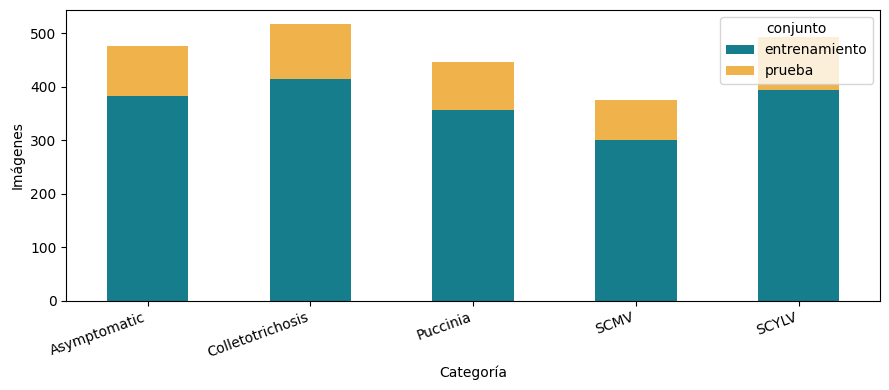

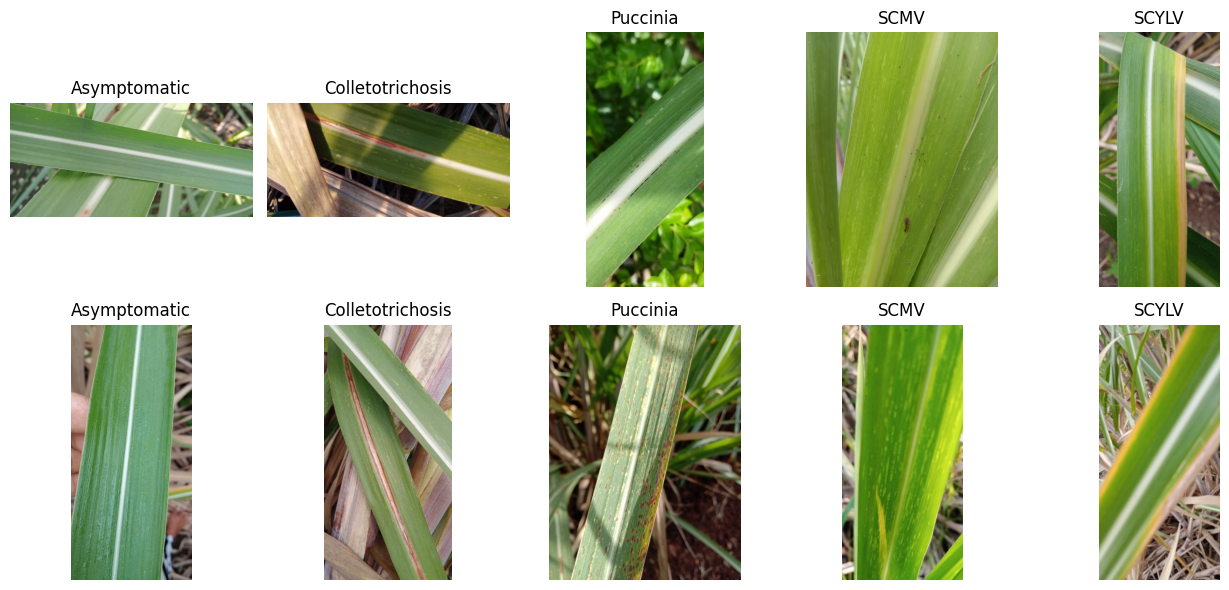

In [ ]:
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_train, idx_test = next(divisor.split(df,df.clase,groups=df.grupo))
assert not set(df.iloc[idx_train].grupo) & set(df.iloc[idx_test].grupo)
df['conjunto'] = 'entrenamiento'
df.loc[idx_test,'conjunto'] = 'prueba'
df.to_csv(SALIDA/'particion_imagenes.csv',index=False)
conteos = pd.crosstab(df.clase,df.conjunto).reindex(CLASES)
conteos.to_csv(SALIDA/'conteos_clases.csv')
print(conteos.to_string())
print('Entrenamiento:',len(idx_train),'Prueba:',len(idx_test))
conteos.plot.bar(stacked=True,figsize=(9,4),color=['#167d8d','#f0b34b'])
plt.ylabel('Imágenes'); plt.xlabel('Categoría');plt.xticks(rotation=20,ha='right')
plt.tight_layout();plt.savefig(SALIDA/'distribucion_clases.png',dpi=170);plt.show()
fig,axes=plt.subplots(2,5,figsize=(13,6))
for j,c in enumerate(CLASES):
    muestra = df[(df.clase==c)&(df.conjunto=='entrenamiento')].sample(2,random_state=SEED)
    for ax,(_,fila) in zip(axes[:,j],muestra.iterrows()):
        ax.imshow(leer_rgb(DATASET/fila.archivo));ax.set_title(c);ax.axis('off')
fig.tight_layout();fig.savefig(SALIDA/'ejemplos_entrenamiento.png',dpi=140);plt.show()


### Resultados de la división de los datos

Después de realizar la limpieza del dataset, trabajamos con un total de 2.311 imágenes. De estas, 1.851 se utilizaron para entrenamiento y 460 se reservaron para prueba, lo que corresponde aproximadamente al 80 % y 20 %, respectivamente.

En la primera gráfica podemos observar cómo se distribuyeron las imágenes de cada categoría entre ambos conjuntos. Aunque no todas las categorías tienen exactamente la misma cantidad de fotografías, se mantuvo una distribución similar entre entrenamiento y prueba.

También seleccionamos algunas fotografías de cada categoría para observar las diferencias visuales entre las hojas. En estas imágenes podemos identificar variaciones en el color, las manchas y las franjas que presentan algunas hojas, así como diferencias en el fondo y la iluminación.

Esta exploración nos permite conocer mejor los datos con los que vamos a trabajar y entender por qué las características de color y textura pueden ser útiles para realizar la clasificación.

## 5. Extracción de características de color y textura

En esta parte del proyecto convertimos cada fotografía en un conjunto de valores numéricos que nos permiten analizar sus características de color y textura.

Para realizar este procedimiento, trabajamos con 44 características distribuidas de la siguiente manera:

- **Color RGB (6 características):** calculamos el promedio y la desviación estándar de los canales rojo, verde y azul. Esto nos permite conocer los colores predominantes y cómo varían dentro de cada fotografía.

- **Espacio de color HSV (32 características):** utilizamos histogramas para analizar el tono (16 intervalos), la saturación (8 intervalos) y el brillo (8 intervalos). Con esto podemos representar mejor las diferencias de color presentes en las hojas.

- **Entropía (1 característica):** calculamos la variación de las intensidades de gris de la imagen, lo que nos ayuda a describir qué tan diversa es su información visual.

- **Textura GLCM (5 características):** analizamos el contraste, la disimilitud, la homogeneidad, la energía angular (ASM) y la correlación. Estas variables permiten describir cómo se distribuyen las intensidades de los píxeles y las diferencias de textura dentro de las fotografías.

Antes de extraer estas características, ajustamos las imágenes para que su lado más largo tuviera 256 píxeles, conservando sus proporciones.

En esta primera extracción utilizamos las fotografías completas, por lo que las características obtenidas también pueden estar influenciadas por el fondo, las sombras y las condiciones de iluminación.

Con estos valores buscamos representar cada imagen mediante información numérica que posteriormente será utilizada para entrenar y comparar los modelos de clasificación.


In [ ]:
NOMBRES = [f'rgb_{c}_{est}' for est in ['media','desviacion'] for c in 'rgb']
NOMBRES += [f'hsv_{c}_bin_{b:02d}' for c,n in [('h',16),('s',8),('v',8)] for b in range(n)]
NOMBRES += ['entropia_gris','contraste','disimilitud','homogeneidad','ASM','correlacion']

def caracteristicas(ruta):
    im = leer_rgb(ruta)
    im.thumbnail((256,256),Image.Resampling.LANCZOS)
    rgb = np.asarray(im,dtype=float)/255.0
    f = list(rgb.mean(axis=(0,1))) + list(rgb.std(axis=(0,1)))
    hsv = np.asarray(im.convert('HSV'),dtype=float)/255.0
    for canal,n in enumerate([16,8,8]):
        hist,_ = np.histogram(hsv[:,:,canal],bins=n,range=(0,1))
        f.extend(hist/hist.sum())
    gris = np.asarray(im.convert('L'))
    h = np.bincount(gris.ravel(),minlength=256).astype(float)
    h = h[h>0]/h.sum()
    f.append(float(-(h*np.log2(h)).sum()))
    q = (gris//16).astype(int)
    vecinos = [(q[:,:-1],q[:,1:]),(q[:-1,:],q[1:,:]),
               (q[:-1,:-1],q[1:,1:]),(q[:-1,1:],q[1:,:-1])]
    ii,jj = np.indices((16,16))
    texturas = []
    for a,b in vecinos:
        m = np.bincount((a.ravel()*16+b.ravel()),minlength=256).reshape(16,16).astype(float)
        m = m + m.T
        m = m/m.sum()
        mi,mj = (ii*m).sum(),(jj*m).sum()
        si,sj = np.sqrt(((ii-mi)**2*m).sum()),np.sqrt(((jj-mj)**2*m).sum())
        corr = (((ii-mi)*(jj-mj)*m).sum()/(si*sj)) if si*sj>0 else 1.0
        texturas.append([(((ii-jj)**2)*m).sum(),(abs(ii-jj)*m).sum(),
                         (m/(1+(ii-jj)**2)).sum(),(m*m).sum(),corr])
    f.extend(np.mean(texturas,axis=0))
    return np.asarray(f,dtype=float)

filas = []
for i,fila in df.iterrows():
    filas.append(caracteristicas(DATASET/fila.archivo))
    if (i+1)%500==0: print('Procesadas',i+1,'imágenes')
X = np.vstack(filas)
y = df.clase.to_numpy()
assert X.shape == (len(df),len(NOMBRES)) and np.isfinite(X).all()
tabla = pd.concat([df[['archivo','clase','grupo','conjunto']],pd.DataFrame(X,columns=NOMBRES)],axis=1)
tabla.to_csv(SALIDA/'caracteristicas.csv',index=False)
print('X:',X.shape,'y:',y.shape)
print(tabla.iloc[:3,:10].round(3).to_string(index=False))


Procesadas 500 imágenes
Procesadas 1000 imágenes
Procesadas 1500 imágenes
Procesadas 2000 imágenes
X: (2311, 44) y: (2311,)
                                            archivo        clase  grupo conjunto  rgb_r_media  rgb_g_media  rgb_b_media  rgb_r_desviacion  rgb_g_desviacion  rgb_b_desviacion
  Sugarcane Dataset/Asymptomatic/asymptomatic_1.jpg Asymptomatic      0   prueba        0.466        0.491        0.355             0.163             0.168             0.165
 Sugarcane Dataset/Asymptomatic/asymptomatic_10.jpg Asymptomatic      1   prueba        0.472        0.582        0.524             0.181             0.105             0.124
Sugarcane Dataset/Asymptomatic/asymptomatic_100.jpg Asymptomatic      2   prueba        0.332        0.441        0.280             0.200             0.193             0.189


### Resultados de la extracción de características

Después de procesar las imágenes, obtuvimos una matriz de datos con 2.311 registros y 44 características numéricas para cada fotografía.

Esto significa que logramos transformar las imágenes en valores relacionados con su color y textura, los cuales utilizaremos posteriormente para entrenar los modelos de clasificación.

Al observar las primeras filas de la tabla, podemos ver que los valores de los canales RGB cambian entre fotografías, incluso cuando pertenecen a la misma categoría. Esto nos muestra que las imágenes presentan diferencias visuales que pueden estar relacionadas con las hojas, el fondo y las condiciones de iluminación.

También comprobamos que cada fotografía conserva su categoría original, lo que nos permite relacionar las características extraídas con las etiquetas del dataset.

Con estos resultados ya tenemos preparada la información numérica necesaria para continuar con el entrenamiento y la comparación de los modelos.

## 6. Entrenamiento y comparación de modelos de clasificación

Después de extraer las 44 características de cada fotografía, utilizamos estos datos para comparar diferentes modelos de aprendizaje supervisado y determinar cuál permite clasificar mejor las cinco categorías de hojas de caña de azúcar.

Para realizar la comparación trabajamos con los siguientes modelos:

- **Modelo de referencia:** predice siempre la categoría más frecuente. Lo utilizamos como punto de comparación para conocer si los otros modelos realmente ofrecen mejores resultados.

- **Naive Bayes:** es un modelo probabilístico que utiliza las características de las imágenes para estimar a qué categoría pertenece cada fotografía. En este caso utilizamos Gaussian Naive Bayes, que trabaja bajo el supuesto de independencia entre las características.

- **SVM (máquina de vectores de soporte):** busca establecer límites que permitan separar las categorías a partir de sus características. Utilizamos un kernel RBF, que permite trabajar con relaciones no lineales, y comparamos dos valores del parámetro C: 1 y 10.

### Evaluación de los modelos

Para comparar su desempeño utilizamos validación cruzada de tres bloques, manteniendo agrupadas las imágenes similares para reducir el riesgo de que aparezcan en entrenamiento y validación.

La principal métrica utilizada fue el **F1 macro**, que considera el desempeño de todas las categorías y les da la misma importancia.

También calculamos la exactitud para conocer la proporción general de clasificaciones correctas.

Antes de entrenar los modelos, aplicamos una estandarización de las características dentro de cada pipeline. Esto permite ajustar los datos utilizando únicamente la información correspondiente al entrenamiento de cada división.

Finalmente, comparamos los resultados de la validación cruzada para seleccionar el modelo con mejor desempeño, sin utilizar todavía las imágenes reservadas para la prueba final.


In [ ]:
X_train,X_test = X[idx_train],X[idx_test]
y_train,y_test = y[idx_train],y[idx_test]
g_train = df.iloc[idx_train].grupo.to_numpy()
cv = list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED).split(X_train,y_train,g_train))
modelos = {
    'Referencia': DummyClassifier(strategy='most_frequent'),
    'Naive_Bayes': make_pipeline(StandardScaler(),GaussianNB()),
    'SVM_C1': make_pipeline(StandardScaler(),SVC(C=1,kernel='rbf',gamma='scale')),
    'SVM_C10': make_pipeline(StandardScaler(),SVC(C=10,kernel='rbf',gamma='scale')),
}
resumen_cv = []
for nombre,modelo in modelos.items():
    resultados = cross_validate(modelo,X_train,y_train,cv=cv,
                               scoring={'f1_macro':'f1_macro','accuracy':'accuracy'},n_jobs=1)
    resumen_cv.append({'modelo':nombre,'f1_macro_media':resultados['test_f1_macro'].mean(),
                       'f1_macro_desviacion':resultados['test_f1_macro'].std(),
                       'accuracy_media':resultados['test_accuracy'].mean()})
validacion = pd.DataFrame(resumen_cv).sort_values('f1_macro_media',ascending=False)
validacion.to_csv(SALIDA/'comparacion_validacion.csv',index=False)
GANADOR = validacion.iloc[0]['modelo']
print(validacion.round(4).to_string(index=False))
print('Seleccionado antes de evaluar la prueba:',GANADOR)


     modelo  f1_macro_media  f1_macro_desviacion  accuracy_media
    SVM_C10          0.8036               0.0166          0.8055
     SVM_C1          0.7618               0.0012          0.7650
Naive_Bayes          0.5373               0.0226          0.5440
 Referencia          0.0733               0.0010          0.2242
Seleccionado antes de evaluar la prueba: SVM_C10


### Resultados de la comparación de modelos

Después de realizar la validación cruzada, encontramos diferencias en el desempeño de los modelos utilizados para clasificar las imágenes de caña de azúcar.

El modelo de referencia obtuvo un F1 macro de 0,0733, mientras que Naive Bayes alcanzó un valor de 0,5373. Esto nos muestra que Naive Bayes logró un mejor desempeño que el modelo que simplemente predice la categoría más frecuente.

Por otro lado, los modelos SVM presentaron los mejores resultados. Con C=1 obtuvimos un F1 macro de 0,7618, mientras que con C=10 alcanzamos un valor de 0,8036.

También observamos que SVM con C=10 obtuvo la mayor exactitud promedio, con un 80,55 % durante la validación cruzada.

A partir de estos resultados, seleccionamos **SVM con C=10** como el modelo con mejor desempeño para continuar con la evaluación final utilizando las imágenes de prueba que habíamos reservado.

Esta comparación nos permitió identificar cuál de los modelos se adaptó mejor a las características de color y textura extraídas de las fotografías.

## 7. Evaluación final de los modelos

Después de comparar los modelos mediante validación cruzada, realizamos la evaluación final utilizando las 460 imágenes que habíamos reservado para prueba.

En esta etapa entrenamos cada modelo con las 1.851 imágenes del conjunto de entrenamiento y posteriormente evaluamos su desempeño con las fotografías de prueba.

Aunque comparamos los resultados de todos los modelos, mantuvimos **SVM con C=10** como el modelo seleccionado, ya que había obtenido el mejor F1 macro durante la validación cruzada.

### Métricas utilizadas

Para evaluar los resultados tuvimos en cuenta las siguientes métricas:

- **Exactitud (accuracy):** indica qué proporción del total de imágenes fue clasificada correctamente.
- **Precisión (precision):** nos muestra qué proporción de las imágenes clasificadas dentro de una categoría realmente pertenece a ella.
- **Sensibilidad (recall):** indica qué proporción de las imágenes que realmente pertenecen a una categoría fue identificada correctamente.
- **F1-score:** combina la precisión y la sensibilidad en una sola medida.
- **F1 macro:** calcula el promedio del F1-score de las cinco categorías, dándole la misma importancia a cada una.

Estas métricas nos permiten analizar el comportamiento de los modelos desde diferentes aspectos, ya que no basta con conocer únicamente el porcentaje general de aciertos.

Con esta evaluación buscamos comprobar qué tan bien se clasifican las imágenes que no fueron utilizadas durante el entrenamiento y conocer las principales diferencias entre los modelos.

     modelo  accuracy  f1_macro  seleccionado_por_validacion
 Referencia    0.2239    0.0732                        False
Naive_Bayes    0.5348    0.5287                        False
     SVM_C1    0.7913    0.7873                        False
    SVM_C10    0.8022    0.7977                         True


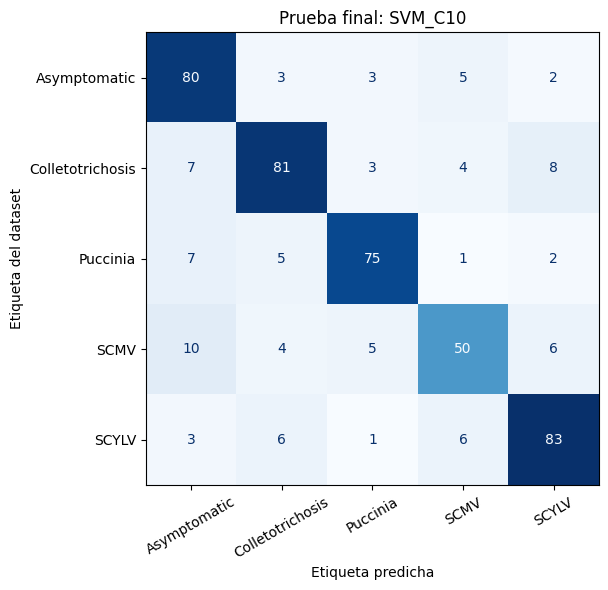

                  precision    recall  f1-score   support

    Asymptomatic       0.75      0.86      0.80        93
Colletotrichosis       0.82      0.79      0.80       103
        Puccinia       0.86      0.83      0.85        90
            SCMV       0.76      0.67      0.71        75
           SCYLV       0.82      0.84      0.83        99

        accuracy                           0.80       460
       macro avg       0.80      0.80      0.80       460
    weighted avg       0.80      0.80      0.80       460



In [ ]:
metricas = []
predicciones = df.iloc[idx_test][['archivo','clase','grupo']].reset_index(drop=True).copy()
for nombre,modelo in modelos.items():
    modelo.fit(X_train,y_train)
    pred = modelo.predict(X_test)
    predicciones[nombre] = pred
    metricas.append({'modelo':nombre,'accuracy':accuracy_score(y_test,pred),
                     'f1_macro':f1_score(y_test,pred,average='macro',zero_division=0),
                     'seleccionado_por_validacion':nombre==GANADOR})
    reporte = classification_report(y_test,pred,labels=CLASES,output_dict=True,zero_division=0)
    pd.DataFrame(reporte).T.to_csv(SALIDA/f'reporte_{nombre}.csv')
metricas = pd.DataFrame(metricas)
metricas.to_csv(SALIDA/'metricas_prueba.csv',index=False)
predicciones.to_csv(SALIDA/'predicciones_prueba.csv',index=False)
print(metricas.round(4).to_string(index=False))
pred = predicciones[GANADOR].to_numpy()
fig,ax = plt.subplots(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=CLASES,display_labels=CLASES,
                                       cmap='Blues',xticks_rotation=30,ax=ax,colorbar=False)
ax.set_title('Prueba final: '+GANADOR);ax.set_xlabel('Etiqueta predicha');ax.set_ylabel('Etiqueta del dataset')
fig.tight_layout();fig.savefig(SALIDA/'matriz_confusion.png',dpi=170);plt.show()
print(classification_report(y_test,pred,labels=CLASES,zero_division=0))


### Resultados de la evaluación final

Después de evaluar los modelos con las 460 imágenes de prueba, encontramos que SVM con C=10 fue el que obtuvo los mejores resultados, alcanzando una exactitud del 80,22 % y un F1 macro de 0,7977.

Esto significa que el modelo logró clasificar correctamente 369 fotografías, mientras que las 91 restantes fueron clasificadas en categorías diferentes a las originales.

Al comparar los modelos, observamos que Naive Bayes alcanzó una exactitud del 53,48 %, mientras que SVM con C=1 obtuvo un 79,13 %. Estos resultados muestran que las dos configuraciones de SVM lograron un mejor desempeño que Naive Bayes en este conjunto de datos.

### Análisis de la matriz de confusión

Al revisar la matriz de confusión, observamos que algunas categorías fueron más fáciles de identificar que otras.

La categoría Puccinia presentó el mejor F1-score, con un valor de 0,85, seguida de SCYLV con 0,83.

En cambio, SCMV fue la categoría que presentó mayores dificultades, con un F1-score de 0,71. De las 75 fotografías correspondientes a esta categoría, el modelo clasificó correctamente 50, pero confundió 10 con hojas asintomáticas.

También encontramos que algunas fotografías de otras categorías fueron clasificadas como asintomáticas, lo que indica que todavía existen características visuales que el modelo no logra diferenciar completamente.

En general, estos resultados nos muestran que las características de color y textura permiten distinguir las cinco categorías con un desempeño favorable, aunque el modelo todavía presenta errores que deben tenerse en cuenta.

Es importante recordar que estos resultados corresponden a las imágenes de este dataset y no significan que el modelo pueda utilizarse directamente para diagnosticar enfermedades en campo sin una validación adicional.

## 8. Análisis de errores y trazabilidad de los resultados

Después de evaluar el desempeño de los modelos, revisamos las fotografías que no fueron clasificadas correctamente por el SVM con C=10.

Para realizar este análisis utilizamos la matriz de confusión y algunos ejemplos de imágenes en las que el modelo cometió errores.

La matriz de confusión nos permitió identificar cuáles categorías se confunden con mayor frecuencia. Por otro lado, al observar las fotografías clasificadas incorrectamente, podemos examinar algunas características visuales que podrían estar relacionadas con esas confusiones.

Entre los aspectos que nos interesa revisar están las diferencias de iluminación, las sombras, los cambios de color y la presencia de otros elementos en el fondo de las fotografías.

Sin embargo, observar estos ejemplos no nos permite asegurar que el modelo haya utilizado específicamente esas características para tomar sus decisiones.

También conservamos información de las imágenes y de sus predicciones para poder identificar los errores y revisar posteriormente los resultados obtenidos.

Este análisis nos ayuda a reconocer las limitaciones del modelo y a plantear posibles mejoras, como trabajar con imágenes segmentadas para evaluar la influencia del fondo en la clasificación.

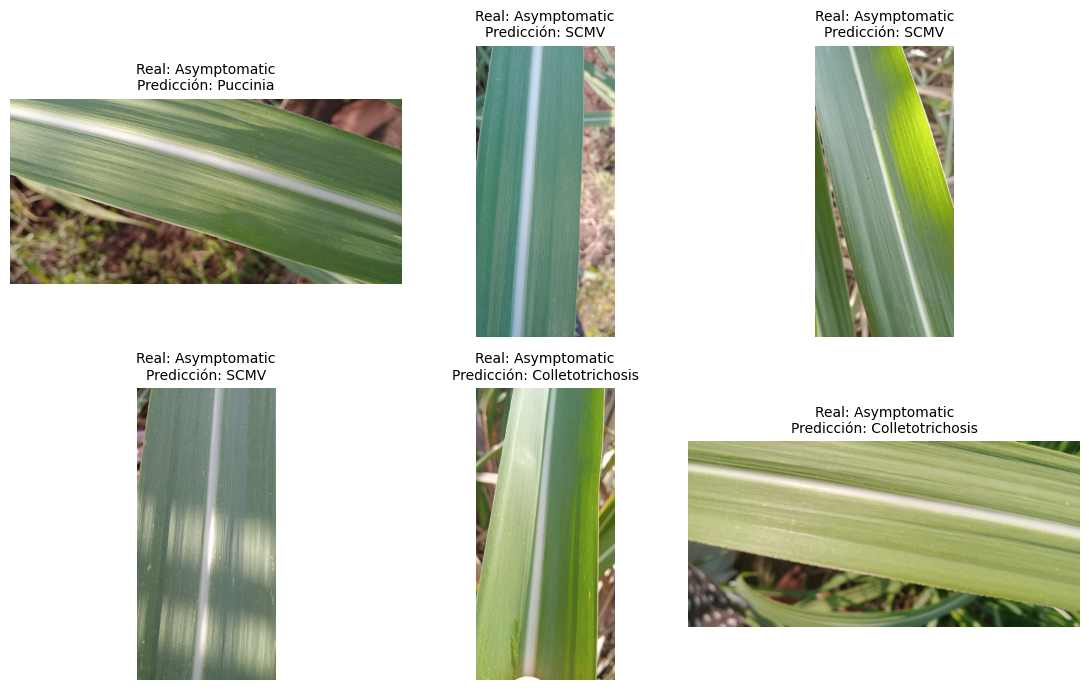

Resultados guardados en: /content/resultados


In [ ]:
malos = np.flatnonzero(y_test != pred)
if len(malos):
    seleccion = malos[:min(6,len(malos))]
    fig,axes = plt.subplots(2,3,figsize=(11,7))
    for ax in axes.ravel(): ax.axis('off')
    for ax,i in zip(axes.ravel(),seleccion):
        ax.imshow(leer_rgb(DATASET/predicciones.iloc[i]['archivo']))
        ax.set_title(f'Real: {y_test[i]}\nPredicción: {pred[i]}',fontsize=10)
    fig.tight_layout();fig.savefig(SALIDA/'errores_ejemplos.png',dpi=140);plt.show()
resumen = {'fuente':'https://www.kaggle.com/datasets/anant1302/sugarcane-leaf-disease-classification-dataset',
           'version_dataset':1,'semilla':SEED,'auditoria':auditoria,'n_entrenamiento':len(idx_train),
           'n_prueba':len(idx_test),'n_caracteristicas':len(NOMBRES),'modelo_seleccionado':GANADOR,
           'versiones':VERSIONES,'metricas_prueba':metricas.to_dict(orient='records')}
(SALIDA/'resumen_ejecucion.json').write_text(json.dumps(resumen,indent=2,ensure_ascii=False),encoding='utf-8')
print('Resultados guardados en:', SALIDA)


### Resultados del análisis de errores

Al revisar algunos de los errores cometidos por el modelo SVM con C=10, encontramos fotografías que originalmente pertenecían a la categoría Asymptomatic, pero fueron clasificadas como hojas con alguna enfermedad.

En los seis ejemplos observados, tres fotografías fueron clasificadas como SCMV, dos como Colletotrichosis y una como Puccinia.

Al observar estas imágenes, podemos identificar diferencias en las tonalidades del verde, algunas franjas claras y cambios de iluminación sobre las hojas. También encontramos fotografías en las que aparecen sombras y otros elementos vegetales en el fondo.

Estas características podrían dificultar la clasificación, ya que algunas variaciones visuales pueden parecerse a los patrones presentes en otras categorías.

Sin embargo, estos ejemplos no permiten determinar exactamente qué características utilizó el modelo para realizar sus predicciones.

Este análisis nos muestra que, aunque el SVM obtuvo buenos resultados generales, todavía puede confundir hojas sin síntomas visibles con otras categorías. Por eso, es importante revisar los errores y no evaluar el desempeño únicamente a partir de la exactitud.

## 9. Segmentación de la hoja y análisis del contexto

Después de evaluar los modelos y revisar algunos de sus errores, quisimos analizar si las características del fondo y las condiciones en las que fueron tomadas las fotografías podían influir en la clasificación.

Al observar las imágenes del dataset, encontramos que algunas incluyen suelo, otras plantas, sombras y diferentes condiciones de iluminación. Además, las fotografías no tienen todas las mismas dimensiones, lo que podría aportar información adicional al modelo.

Por esta razón, realizamos un análisis de segmentación para intentar separar las hojas del fondo y comparar los resultados con los obtenidos anteriormente utilizando las fotografías completas.

### 9.1. Segmentación de las hojas

Para realizar la segmentación utilizamos diferentes técnicas de procesamiento de imágenes:

- **Índice de verde excedente (ExG):** nos permite resaltar las zonas verdes de la fotografía a partir de los canales RGB.
- **Umbral de Otsu:** lo utilizamos para establecer un valor de separación entre las regiones de la imagen.
- **Apertura morfológica:** ayuda a eliminar pequeñas regiones que pueden aparecer como ruido.
- **Cierre morfológico:** permite unir algunas zonas cercanas de la hoja.
- **Relleno de huecos:** ayuda a recuperar regiones internas de la máscara.
- **Componente conexa más grande:** permite conservar la región principal identificada durante la segmentación.

Después de obtener las máscaras, volvimos a calcular las mismas 44 características de color y textura, pero esta vez utilizando únicamente los píxeles seleccionados como parte de la hoja.

Con este procedimiento buscamos comparar el desempeño del modelo cuando trabaja con la fotografía completa y cuando se reduce la influencia del fondo.

Es importante tener en cuenta que la segmentación no es perfecta, ya que en algunas imágenes puede incluir partes de otras hojas o dejar por fuera ciertas zonas de la hoja principal.

Procesadas 500 imágenes
Procesadas 1000 imágenes
Procesadas 1500 imágenes
Procesadas 2000 imágenes
Máscaras fallidas (se usó la imagen completa): 23
Fracción de la imagen ocupada por la hoja, por clase:
                   mean    25%    50%    75%
clase                                       
Asymptomatic      0.583  0.459  0.614  0.737
Colletotrichosis  0.445  0.287  0.431  0.595
Puccinia          0.456  0.300  0.463  0.612
SCMV              0.537  0.399  0.539  0.707
SCYLV             0.485  0.349  0.489  0.633


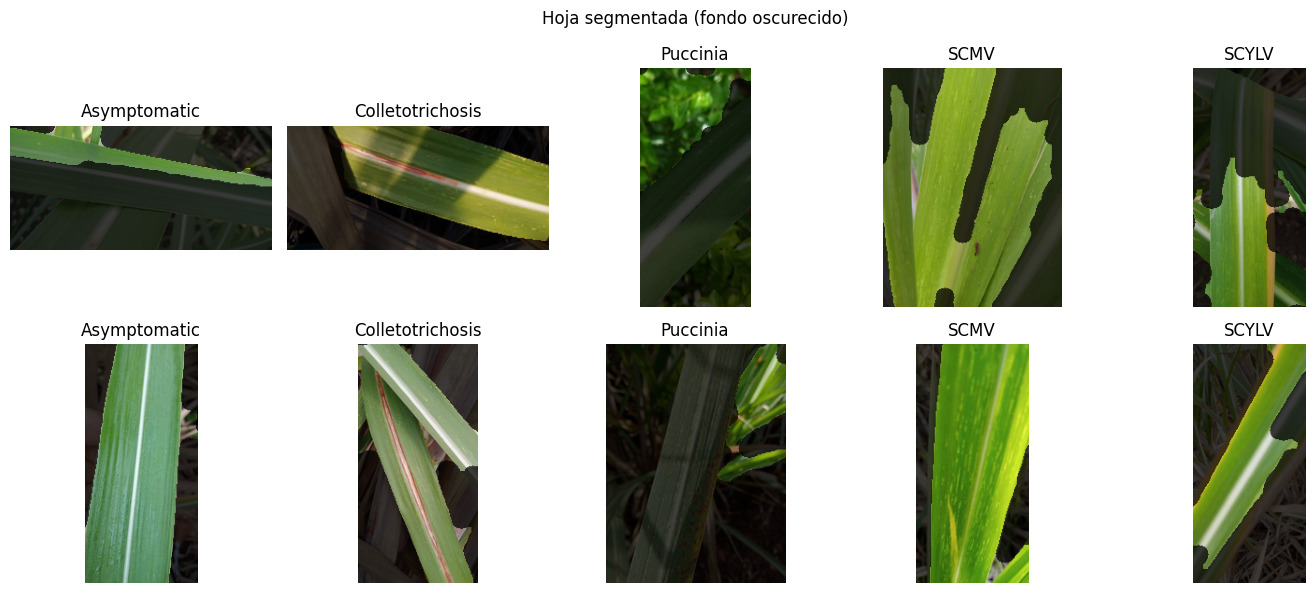

In [ ]:
#Segmentación de la hoja
from scipy import ndimage as ndi
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

def otsu(valores):
    hist, bordes = np.histogram(valores, bins=256)
    centros = (bordes[:-1] + bordes[1:]) / 2
    w0 = np.cumsum(hist); w1 = w0[-1] - w0
    s0 = np.cumsum(hist * centros); total = s0[-1]
    m0 = s0 / np.maximum(w0, 1); m1 = (total - s0) / np.maximum(w1, 1)
    return centros[np.argmax(w0 * w1 * (m0 - m1) ** 2)]

yy, xx = np.mgrid[-10:11, -10:11]
DISCO = (xx**2 + yy**2) <= 100   # elemento estructurante circular, radio 10 px

def mascara_hoja(im):
    """ExG + Otsu + morfología + componente conexa más grande."""
    rgb = np.asarray(im, dtype=float) / 255.0
    suma = rgb.sum(axis=2) + 1e-6
    r, g, b = (rgb[:, :, k] / suma for k in range(3))
    exg = 2 * g - r - b
    m = exg > otsu(exg)
    m = ndi.binary_opening(m, structure=np.ones((5, 5)))
    # cierre amplio: une las dos mitades separadas por la nervadura central blanca
    m = ndi.binary_closing(np.pad(m, 12, mode='edge'), structure=DISCO)[12:-12, 12:-12]
    m = ndi.binary_fill_holes(m)          # recupera lesiones dentro de la hoja
    etiquetas, n = ndi.label(m)
    if n > 0:
        tamanos = ndi.sum(m, etiquetas, range(1, n + 1))
        m = etiquetas == (np.argmax(tamanos) + 1)
    return m

def glcm_props(q, valido):
    H, W = q.shape
    ii, jj = np.indices((16, 16))
    props = []
    for dy, dx in [(0, 1), (1, 0), (1, 1), (1, -1)]:
        fa = (slice(0, H - dy), slice(max(0, -dx), W - max(0, dx)))
        fb = (slice(dy, H), slice(max(0, dx), W - max(0, -dx)))
        ok = valido[fa] & valido[fb]
        a, b = q[fa][ok], q[fb][ok]
        m = np.bincount(a * 16 + b, minlength=256).reshape(16, 16).astype(float)
        m = m + m.T; m = m / max(m.sum(), 1)
        mi, mj = (ii * m).sum(), (jj * m).sum()
        si, sj = np.sqrt(((ii - mi) ** 2 * m).sum()), np.sqrt(((jj - mj) ** 2 * m).sum())
        corr = (((ii - mi) * (jj - mj) * m).sum() / (si * sj)) if si * sj > 0 else 1.0
        props.append([(((ii - jj) ** 2) * m).sum(), (abs(ii - jj) * m).sum(),
                      (m / (1 + (ii - jj) ** 2)).sum(), (m * m).sum(), corr])
    return list(np.mean(props, axis=0))

def caracteristicas_hoja(im, m):
    """Las mismas 44 variables de la sección 5, pero solo con píxeles de la hoja."""
    rgb = np.asarray(im, dtype=float) / 255.0
    px = rgb[m]
    f = list(px.mean(axis=0)) + list(px.std(axis=0))
    hsv = np.asarray(im.convert('HSV'), dtype=float) / 255.0
    for canal, n in enumerate([16, 8, 8]):
        hist, _ = np.histogram(hsv[:, :, canal][m], bins=n, range=(0, 1))
        f.extend(hist / hist.sum())
    gris = np.asarray(im.convert('L'))
    h = np.bincount(gris[m], minlength=256).astype(float)
    h = h[h > 0] / h.sum()
    f.append(float(-(h * np.log2(h)).sum()))
    f.extend(glcm_props((gris // 16).astype(int), m))
    return np.asarray(f, dtype=float)

filas_hoja, fraccion, sin_mascara = [], [], 0
for i, fila in df.iterrows():
    im = leer_rgb(DATASET / fila.archivo)
    im.thumbnail((256, 256), Image.Resampling.LANCZOS)
    m = mascara_hoja(im)
    if m.mean() < 0.05:                   # máscara fallida: se usa la imagen completa
        m = np.ones_like(m); sin_mascara += 1
    fraccion.append(float(m.mean()))
    filas_hoja.append(caracteristicas_hoja(im, m))
    if (i + 1) % 500 == 0: print('Procesadas', i + 1, 'imágenes')
X_hoja = np.vstack(filas_hoja)
assert X_hoja.shape == X.shape and np.isfinite(X_hoja).all()
df['fraccion_hoja'] = fraccion
pd.concat([df[['archivo', 'clase', 'grupo', 'conjunto', 'fraccion_hoja']],
           pd.DataFrame(X_hoja, columns=NOMBRES)], axis=1).to_csv(SALIDA / 'caracteristicas_hoja.csv', index=False)
print('Máscaras fallidas (se usó la imagen completa):', sin_mascara)
print('Fracción de la imagen ocupada por la hoja, por clase:')
print(df.groupby('clase').fraccion_hoja.describe()[['mean', '25%', '50%', '75%']].round(3).to_string())

# Figura de control: 2 ejemplos por clase (solo entrenamiento)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for j, c in enumerate(CLASES):
    muestra = df[(df.clase == c) & (df.conjunto == 'entrenamiento')].sample(2, random_state=SEED)
    for ax, (_, fila) in zip(axes[:, j], muestra.iterrows()):
        im = leer_rgb(DATASET / fila.archivo); im.thumbnail((256, 256), Image.Resampling.LANCZOS)
        rgb = np.asarray(im, dtype=float) / 255.0
        m = mascara_hoja(im)
        ax.imshow(np.where(m[..., None], rgb, rgb * 0.25)); ax.set_title(c); ax.axis('off')
fig.suptitle('Hoja segmentada (fondo oscurecido)')
fig.tight_layout(); fig.savefig(SALIDA / 'mascaras_ejemplos.png', dpi=140); plt.show()



### Resultados de la segmentación

Después de aplicar el procedimiento de segmentación, obtuvimos imágenes en las que el fondo aparece oscurecido y se conservan las regiones identificadas como parte de la hoja.

Al observar los ejemplos, encontramos que en algunas fotografías la segmentación permitió conservar gran parte de la hoja, mientras que en otras se perdieron algunas zonas o se incluyeron elementos del fondo.

Esto nos muestra que el procedimiento funciona de manera aproximada, pero no logra separar completamente la hoja en todos los casos.

También calculamos qué proporción de cada fotografía fue seleccionada por la máscara. Encontramos que la categoría Asymptomatic presentó el mayor promedio, con un 58,3 %, seguida de SCMV con un 53,7 %. Por otro lado, Colletotrichosis presentó el menor promedio, con un 44,5 %.

Además, en 23 fotografías las máscaras no alcanzaron el tamaño mínimo establecido, por lo que se utilizó la imagen completa para extraer sus características.

Estos resultados son importantes porque nos permiten reconocer algunas limitaciones de la segmentación. Si se pierden partes de la hoja o se incluyen regiones del fondo, las características de color y textura pueden cambiar y afectar posteriormente el desempeño del modelo.

Por esta razón, es necesario tener en cuenta la calidad de las máscaras al comparar los resultados de las fotografías completas con los de las hojas segmentadas.

### 9.2. Evaluación de la influencia del contexto en la clasificación

Después de realizar la segmentación, quisimos comprobar si el modelo estaba utilizando principalmente las características de las hojas o si otros elementos de las fotografías también podían influir en sus resultados.

Para analizarlo, realizamos tres comparaciones:

- **Tamaño de las fotografías:** utilizamos un árbol de decisión que trabaja únicamente con el ancho y el alto de las imágenes, sin analizar sus píxeles. Esto nos permite identificar si las dimensiones de las fotografías contienen información relacionada con las categorías.

- **Imagen completa y hoja segmentada:** comparamos el desempeño del SVM con C=10 utilizando las 44 características extraídas de las fotografías completas y las mismas características obtenidas después de segmentar las hojas. Con esto buscamos evaluar cómo cambia la clasificación al reducir la influencia del fondo.

- **Fotografías con una misma resolución:** realizamos una comparación utilizando solamente imágenes de 493 × 1040 píxeles, incluyendo las que tienen esas dimensiones intercambiadas por su orientación. Esto nos permite analizar el comportamiento del modelo cuando se controla una de las diferencias de tamaño entre fotografías.

Para realizar estas comparaciones mantuvimos la división de entrenamiento y prueba establecida anteriormente, utilizando los grupos correspondientes dentro de cada conjunto.

Con estos análisis buscamos comprender mejor de dónde puede provenir el desempeño del modelo y qué tanto podrían influir las características de captura en los resultados obtenidos.

In [ ]:
#¿el modelo aprende el síntoma o el contexto?
X_tam = df[['ancho', 'alto']].to_numpy(dtype=float)
svm10 = make_pipeline(StandardScaler(), SVC(C=10, kernel='rbf', gamma='scale'))
experimentos = {
    'Solo tamaño de la foto (árbol)': (X_tam, DecisionTreeClassifier(max_depth=5, random_state=SEED)),
    'Imagen completa (SVM C=10)': (X, svm10),
    'Solo hoja segmentada (SVM C=10)': (X_hoja, svm10),
}
filas_exp = []
for nombre, (Xe, modelo) in experimentos.items():
    r = cross_validate(clone(modelo), Xe[idx_train], y_train, cv=cv, scoring=['f1_macro', 'accuracy'])
    mod = clone(modelo).fit(Xe[idx_train], y_train)
    p = mod.predict(Xe[idx_test])
    filas_exp.append({'experimento': nombre, 'f1_macro_cv': r['test_f1_macro'].mean(),
                      'f1_macro_cv_desv': r['test_f1_macro'].std(),
                      'accuracy_prueba': accuracy_score(y_test, p),
                      'f1_macro_prueba': f1_score(y_test, p, average='macro')})
comparacion = pd.DataFrame(filas_exp)
comparacion.to_csv(SALIDA / 'ampliacion_comparacion.csv', index=False)
print(comparacion.round(4).to_string(index=False))

# Control de resolución: solo fotos de 493x1040 (o giradas), presentes en varias clases
mismo_tam = ((df.ancho == 493) & (df.alto == 1040)) | ((df.ancho == 1040) & (df.alto == 493))
sub_tr = np.array([i for i in idx_train if mismo_tam.iloc[i]])
sub_te = np.array([i for i in idx_test if mismo_tam.iloc[i]])
print('\nSubconjunto de una sola resolución:')
print(pd.crosstab(df.loc[mismo_tam, 'clase'], df.loc[mismo_tam, 'conjunto']).to_string())
filas_sub = []
for nombre, Xe in [('Imagen completa', X), ('Solo hoja', X_hoja)]:
    mod = clone(svm10).fit(Xe[sub_tr], y[sub_tr])
    p = mod.predict(Xe[sub_te])
    filas_sub.append({'variables': nombre, 'n_entrenamiento': len(sub_tr), 'n_prueba': len(sub_te),
                      'clases': int(len(np.unique(y[sub_te]))),
                      'accuracy_prueba': accuracy_score(y[sub_te], p),
                      'f1_macro_prueba': f1_score(y[sub_te], p, average='macro')})
subconjunto = pd.DataFrame(filas_sub)
subconjunto.to_csv(SALIDA / 'subconjunto_resolucion.csv', index=False)
print(subconjunto.round(4).to_string(index=False))



                    experimento  f1_macro_cv  f1_macro_cv_desv  accuracy_prueba  f1_macro_prueba
 Solo tamaño de la foto (árbol)       0.4987            0.0076           0.5500           0.4819
     Imagen completa (SVM C=10)       0.8036            0.0166           0.8022           0.7977
Solo hoja segmentada (SVM C=10)       0.7298            0.0009           0.7457           0.7395

Subconjunto de una sola resolución:
conjunto          entrenamiento  prueba
clase                                  
Asymptomatic                249      63
Colletotrichosis            179      48
SCMV                        119      36
SCYLV                       352      88
      variables  n_entrenamiento  n_prueba  clases  accuracy_prueba  f1_macro_prueba
Imagen completa              899       235       4           0.8383           0.8162
      Solo hoja              899       235       4           0.7702           0.7468


### Resultados del análisis del contexto

Después de realizar las comparaciones, encontramos que el modelo SVM con C=10 obtuvo el mejor desempeño cuando utilizamos las características de la fotografía completa, con un F1 macro de 0,7977 y una exactitud del 80,22 %.

Al trabajar únicamente con las características de la hoja segmentada, el F1 macro disminuyó a 0,7395 y la exactitud a 74,57 %. Esto nos muestra que las características de las hojas contienen información útil para realizar la clasificación, aunque el desempeño fue menor que cuando utilizamos las imágenes completas.

También evaluamos un modelo que solamente utilizaba el ancho y el alto de las fotografías. Aunque no analizaba directamente los colores ni las texturas, obtuvo un F1 macro de 0,4819. Este resultado nos llamó la atención porque indica que las dimensiones de las imágenes también están relacionadas con las categorías del dataset.

### Comparación con fotografías de una misma resolución

Para complementar el análisis, trabajamos con un subconjunto de fotografías de una misma resolución, conformado por 899 imágenes de entrenamiento y 235 de prueba, correspondientes a cuatro categorías.

En este caso, el modelo con las imágenes completas alcanzó un F1 macro de 0,8162, mientras que con las hojas segmentadas obtuvo 0,7468.

Aunque estos resultados muestran que el modelo mantiene un buen desempeño cuando trabajamos con fotografías de dimensiones similares, debemos tener en cuenta que esta comparación se realizó con cuatro categorías y no con las cinco del análisis principal.

### Interpretación general

A partir de estos experimentos, encontramos que las características de color y textura de las hojas aportan información importante para la clasificación. Sin embargo, también observamos que el tamaño y las condiciones de captura de las fotografías pueden estar relacionados con los resultados obtenidos.

No podemos asegurar que la diferencia entre las fotografías completas y las hojas segmentadas se deba únicamente al fondo, ya que durante la segmentación algunas máscaras no lograron conservar completamente las hojas.

Por esta razón, consideramos que sería importante mejorar la segmentación y evaluar el modelo con nuevas fotografías tomadas en condiciones diferentes, especialmente en cultivos colombianos.

### 9.3. Ajuste de hiperparámetros y evaluación complementaria del modelo

Después de comparar las imágenes completas y las hojas segmentadas, realizamos un análisis complementario para revisar el comportamiento del modelo SVM al ajustar sus parámetros.

Para esto utilizamos `GridSearchCV`, una herramienta que nos permite probar diferentes combinaciones de los parámetros **C y gamma** y comparar sus resultados mediante validación cruzada.

El parámetro C controla cuánto penaliza el modelo los errores de clasificación durante el entrenamiento, mientras que gamma influye en la forma de los límites que utiliza el SVM para separar las categorías.

La selección de los parámetros se realizó utilizando únicamente los datos de entrenamiento y tomando como referencia el F1 macro obtenido durante la validación.

Después de seleccionar la mejor combinación, evaluamos su desempeño con las imágenes de prueba.

También calculamos un intervalo de confianza del 95 % mediante 1.000 remuestreos bootstrap. Este procedimiento nos permite estimar la variación que podrían presentar las métricas obtenidas a partir del conjunto de prueba.

Es importante aclarar que, como anteriormente ya habíamos revisado los resultados de prueba de diferentes variantes, este procedimiento se presenta como un análisis complementario. Por lo tanto, mantenemos como resultado principal la evaluación del SVM con C=10 presentada en la sección 7.


Variables elegidas por validación: Imagen completa (SVM C=10)
Mejores hiperparámetros: {'svc__C': 10, 'svc__gamma': 'scale'} F1 macro CV: 0.8036
{
  "variables": "Imagen completa (SVM C=10)",
  "hiperparametros": {
    "svc__C": 10,
    "svc__gamma": "scale"
  },
  "f1_macro_cv": 0.8035759293450028,
  "accuracy_prueba": 0.8021739130434783,
  "accuracy_IC95": [
    0.7652173913043478,
    0.8370108695652174
  ],
  "f1_macro_prueba": 0.797731536658895,
  "f1_macro_IC95": [
    0.7577365300477534,
    0.8334807646923009
  ],
  "mascaras_fallidas": 23
}
                  precision    recall  f1-score   support

    Asymptomatic       0.75      0.86      0.80        93
Colletotrichosis       0.82      0.79      0.80       103
        Puccinia       0.86      0.83      0.85        90
            SCMV       0.76      0.67      0.71        75
           SCYLV       0.82      0.84      0.83        99

        accuracy                           0.80       460
       macro avg       0.80      0.

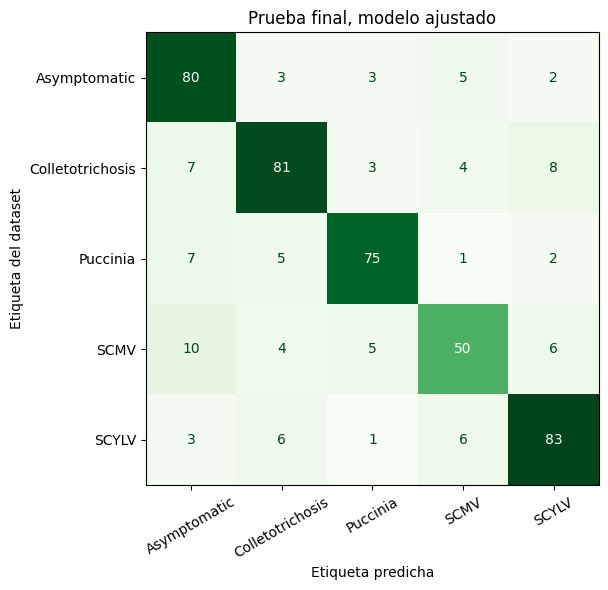

1658

In [ ]:
#ajuste de C y gamma (solo entrenamiento) y prueba final
mejor_cv = comparacion.iloc[1:].sort_values('f1_macro_cv', ascending=False).iloc[0]['experimento']
X_final = X_hoja if 'hoja' in mejor_cv else X
print('\nVariables elegidas por validación:', mejor_cv)
busqueda = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='rbf')),
                        {'svc__C': [1, 3, 10, 30, 100], 'svc__gamma': ['scale', 0.01, 0.03, 0.1]},
                        cv=cv, scoring='f1_macro', n_jobs=-1)
busqueda.fit(X_final[idx_train], y_train)
print('Mejores hiperparámetros:', busqueda.best_params_, 'F1 macro CV:', round(busqueda.best_score_, 4))
p_final = busqueda.predict(X_final[idx_test])

rng = np.random.default_rng(SEED)
boot_acc, boot_f1 = [], []
for _ in range(1000):
    k = rng.integers(0, len(y_test), len(y_test))
    boot_acc.append(accuracy_score(y_test[k], p_final[k]))
    boot_f1.append(f1_score(y_test[k], p_final[k], average='macro'))
final = {'variables': mejor_cv, 'hiperparametros': busqueda.best_params_,
         'f1_macro_cv': busqueda.best_score_,
         'accuracy_prueba': accuracy_score(y_test, p_final),
         'accuracy_IC95': list(np.percentile(boot_acc, [2.5, 97.5])),
         'f1_macro_prueba': f1_score(y_test, p_final, average='macro'),
         'f1_macro_IC95': list(np.percentile(boot_f1, [2.5, 97.5])),
         'mascaras_fallidas': sin_mascara}
print(json.dumps(final, indent=2, ensure_ascii=False, default=float))
print(classification_report(y_test, p_final, labels=CLASES, zero_division=0))
pd.DataFrame(classification_report(y_test, p_final, labels=CLASES, output_dict=True, zero_division=0)).T \
  .to_csv(SALIDA / 'reporte_final_ajustado.csv')
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, p_final, labels=CLASES, cmap='Greens',
                                        xticks_rotation=30, ax=ax, colorbar=False)
ax.set_title('Prueba final, modelo ajustado'); ax.set_xlabel('Etiqueta predicha'); ax.set_ylabel('Etiqueta del dataset')
fig.tight_layout(); fig.savefig(SALIDA / 'matriz_confusion_final.png', dpi=170); plt.show()
(SALIDA / 'ampliacion_resumen.json').write_text(json.dumps(
    {'final': final, 'comparacion': comparacion.to_dict(orient='records'),
     'subconjunto_resolucion': subconjunto.to_dict(orient='records')},
    indent=2, ensure_ascii=False, default=float), encoding='utf-8')


### Resultados del ajuste de hiperparámetros

Después de realizar la búsqueda de hiperparámetros, encontramos que la mejor configuración fue SVM con C=10 y gamma=scale, utilizando las características de las fotografías completas.

Esta configuración obtuvo un F1 macro de 0,8036 durante la validación cruzada, por lo que coincidió con el modelo que habíamos seleccionado anteriormente.

En la evaluación con las 460 imágenes de prueba, obtuvimos una exactitud del 80,22 % y un F1 macro de 0,7977. Estos resultados también coinciden con los presentados en la sección 7.

Además, mediante 1.000 remuestreos bootstrap calculamos un intervalo de confianza del 95 % para la exactitud, comprendido entre 76,52 % y 83,70 %. Para el F1 macro, el intervalo obtenido fue de 0,7577 a 0,8335.

Estos intervalos nos permiten expresar la incertidumbre de las métricas obtenidas, aunque no garantizan que el modelo tenga el mismo desempeño con fotografías tomadas en condiciones diferentes.

En general, este análisis complementario confirmó la configuración que habíamos seleccionado mediante validación cruzada. Sin embargo, mantenemos como resultado principal el de la sección 7, ya que las imágenes de prueba habían sido utilizadas previamente para comparar otras variantes del análisis.

## 10. Guardar y descargar los resultados

Una vez finalizado el procesamiento de las imágenes y la evaluación de los modelos, guardamos los resultados obtenidos durante el proyecto.

Para facilitar su almacenamiento y revisión, reunimos los archivos generados en una carpeta y los comprimimos en un archivo ZIP.

Esto nos permite conservar las tablas, las gráficas y los resultados de los análisis realizados, además de facilitar su consulta y organización dentro del repositorio del proyecto.

También conservamos el notebook de Google Colab, donde se encuentra el código utilizado para desarrollar cada procedimiento y obtener los resultados presentados en el artículo científico.

In [ ]:
import shutil
archivo = shutil.make_archive('resultados_equipo8', 'zip', SALIDA)
print('Creado:', archivo)
try:
    from google.colab import files
    files.download(archivo)
except ImportError:
    print('Fuera de Colab: el ZIP quedó en la carpeta actual.')

Creado: /content/resultados_equipo8.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusiones y limitaciones del proyecto

A partir del análisis realizado, encontramos que las características de color y textura permiten diferenciar las cinco categorías de hojas de caña de azúcar presentes en el dataset.

Inicialmente trabajamos con 2.521 fotografías, de las cuales eliminamos 210 duplicadas exactas. Con las 2.311 imágenes restantes realizamos la extracción de 44 características numéricas y posteriormente comparamos los modelos de clasificación.

Entre los modelos evaluados, SVM con C=10 presentó el mejor desempeño, alcanzando una exactitud del 80,22 % y un F1 macro de 0,7977 en las imágenes de prueba. Esto nos muestra que fue el modelo que mejor logró diferenciar las categorías dentro de los métodos que comparamos.

Sin embargo, al analizar la matriz de confusión, encontramos que algunas categorías fueron más difíciles de reconocer. Principalmente, el modelo presentó dificultades con SCMV, que en varios casos fue confundida con hojas asintomáticas.

Otro resultado importante fue que las características del contexto de las fotografías también pueden estar relacionadas con la clasificación. Al trabajar solamente con el tamaño de las imágenes, obtuvimos un F1 macro de 0,4819, mientras que con las hojas segmentadas alcanzamos 0,7395.

Esto nos permitió observar que las características de la hoja contienen información útil, pero también que las condiciones de captura y las limitaciones de la segmentación pueden influir en los resultados.

### Limitaciones y posibles mejoras

Aunque obtuvimos resultados favorables, debemos tener en cuenta que trabajamos con las etiquetas originales del dataset y no realizamos una confirmación de las enfermedades en laboratorio.

Además, la segmentación no logró separar correctamente las hojas en todas las fotografías, por lo que sería importante mejorar este procedimiento para futuros análisis.

También sería necesario evaluar el modelo con fotografías tomadas en cultivos colombianos y bajo diferentes condiciones de iluminación, fondo y estado de las plantas.

En conclusión, consideramos que este trabajo demuestra cómo el procesamiento de imágenes y los modelos de aprendizaje supervisado pueden apoyar el análisis de enfermedades foliares en caña de azúcar. Sin embargo, el modelo todavía requiere evaluaciones adicionales antes de utilizarse como una herramienta de apoyo en campo.

## Fuentes
- Consigna del trabajo final y sesiones 9, 10 y 11 proporcionadas por el equipo (EAFIT, Big Data y Bioinformática).
- Dataset: https://www.kaggle.com/datasets/anant1302/sugarcane-leaf-disease-classification-dataset (versión 1).
- Naive Bayes: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
- SVM: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
- Evitar fuga de información: https://scikit-learn.org/stable/common_pitfalls.html
- Partición por grupos: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html
